# Emoji-based Sentiment Classification — Offline Demo

Runs **without internet and without retraining**. It only reads the `emoji_sentiment_artifacts` folder produced by the training notebook.

**On Kaggle:** *Add Input → Your Work / Notebooks →* select the training notebook (its output contains the artifacts). Internet can be **OFF**.
**On a laptop:** unzip `emoji_sentiment_artifacts.zip` next to this notebook (or set the `EMOJI_ART` environment variable to its path). Needs `torch`, `transformers`, `pandas`, `matplotlib` installed beforehand; `emoji` installs from the bundled wheel.

In [12]:
import os, sys, glob, json, subprocess, time
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_DATASETS_OFFLINE"] = "1"

def find_artifacts():
    cands = [os.environ.get("EMOJI_ART", ""), "emoji_sentiment_artifacts", "../emoji_sentiment_artifacts",
             "/kaggle/working/emoji_sentiment_artifacts"]
    cands += [os.path.dirname(p) for p in glob.glob("/kaggle/input/**/manifest.json", recursive=True)]
    for c in cands:
        if c and os.path.exists(os.path.join(c, "manifest.json")) and os.path.isdir(os.path.join(c, "models")):
            return os.path.abspath(c)
    raise FileNotFoundError("Could not find emoji_sentiment_artifacts/ — attach the training output or set EMOJI_ART.")

ART = find_artifacts()
print("Artifacts:", ART)

try:
    import emoji
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--no-index",
                           "--find-links", os.path.join(ART, "wheels"), "emoji"])
    import emoji

sys.path.insert(0, ART)
import pandas as pd, numpy as np, torch
import emoji_sentiment_lib as esl
manifest = json.load(open(os.path.join(ART, "manifest.json")))
print("Trained on", manifest["created"], "| versions:", manifest["versions"])

Artifacts: o:\studies sem 7\DL\project\v2\emoji_sentiment_artifacts
Trained on 2026-10-28 22:36:21 | versions: {'torch': '2.11.0+cu128', 'transformers': '5.16.1', 'emoji': '2.16.0', 'python': '3.13.15'}


In [3]:
t0 = time.time()
predictor = esl.SentimentPredictor(ART)
print(f"Loaded models B, C, D on {predictor.device} in {time.time() - t0:.1f}s (from disk, no internet)")

o:\studies sem 7\DL\project\v2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 104/104 [00:00<00:00, 17342.17it/s]


Loaded models B, C, D on cpu in 8.2s (from disk, no internet)


## Saved results (no re-run needed)

In [4]:
res = pd.read_csv(os.path.join(ART, "results.csv"))
order = ["full_test", "emoji_tweets", "emoji_only"]
print("Macro-F1"); display(res.pivot(index="model", columns="eval_set", values="macro_f1").round(4)[order])
print("Accuracy"); display(res.pivot(index="model", columns="eval_set", values="accuracy").round(4)[order])
print("Test-set sizes:", res.drop_duplicates("eval_set").set_index("eval_set")["n"].to_dict())

Macro-F1


eval_set,full_test,emoji_tweets,emoji_only
model,,,
B_raw,0.7093,0.6812,0.1647
C_demoji,0.7179,0.7008,0.4605
D_gated,0.7198,0.7128,0.5018


Accuracy


eval_set,full_test,emoji_tweets,emoji_only
model,,,
B_raw,0.7082,0.6966,0.3282
C_demoji,0.7177,0.7214,0.5015
D_gated,0.7210,0.7368,0.5604


Test-set sizes: {'full_test': 4914, 'emoji_tweets': 323, 'emoji_only': 323}


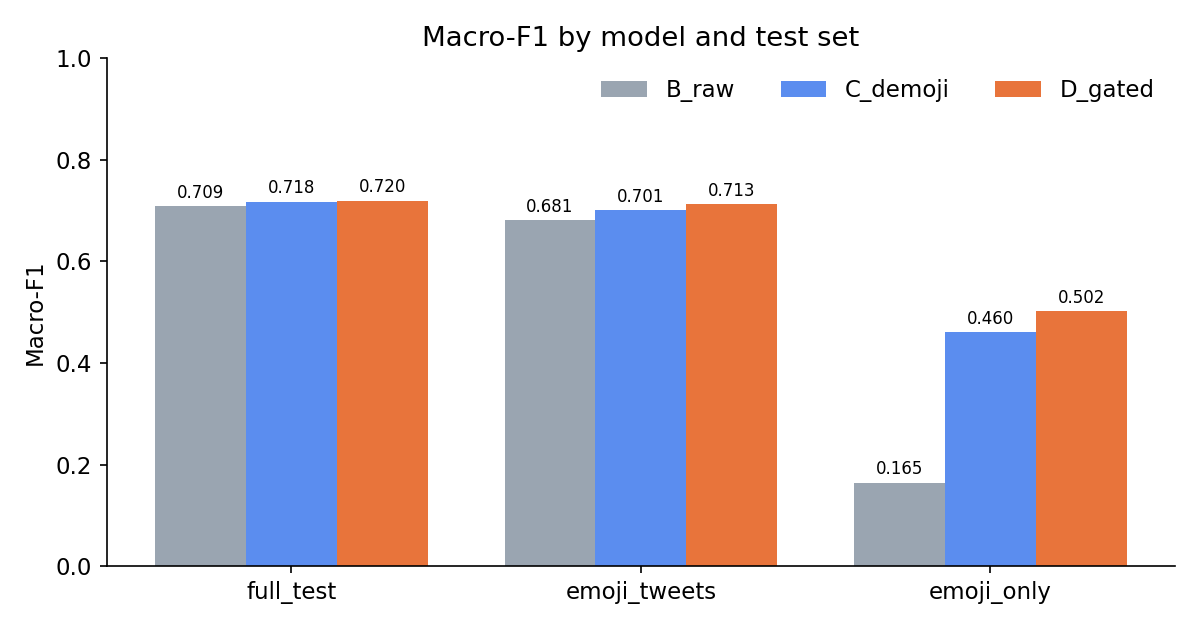

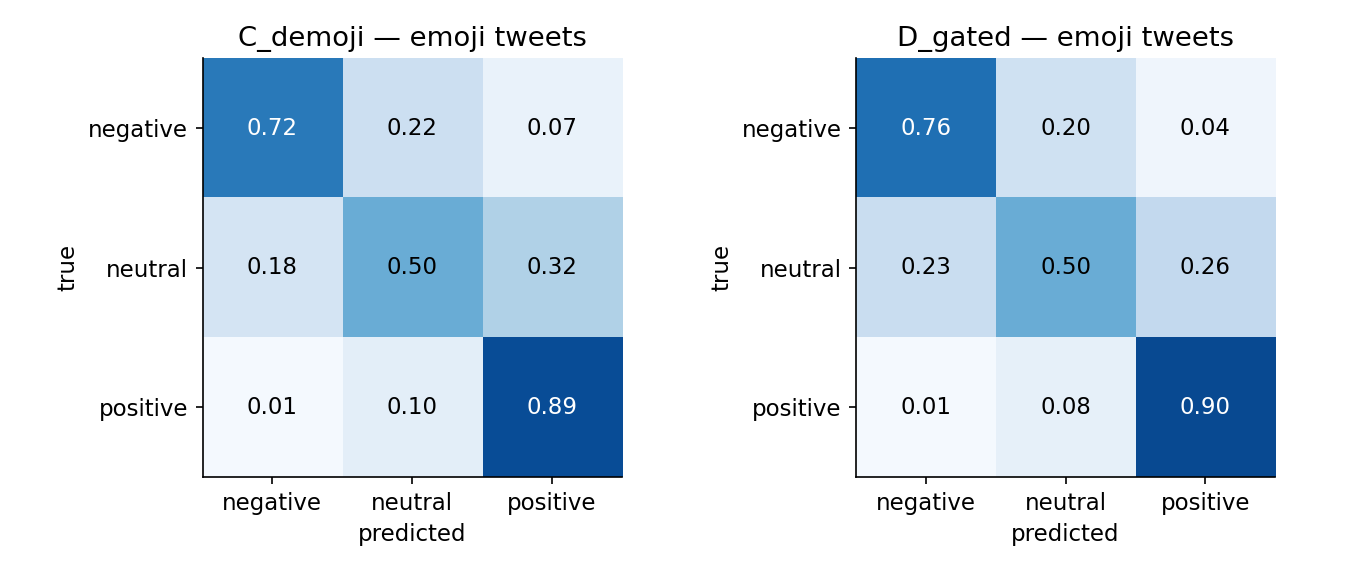

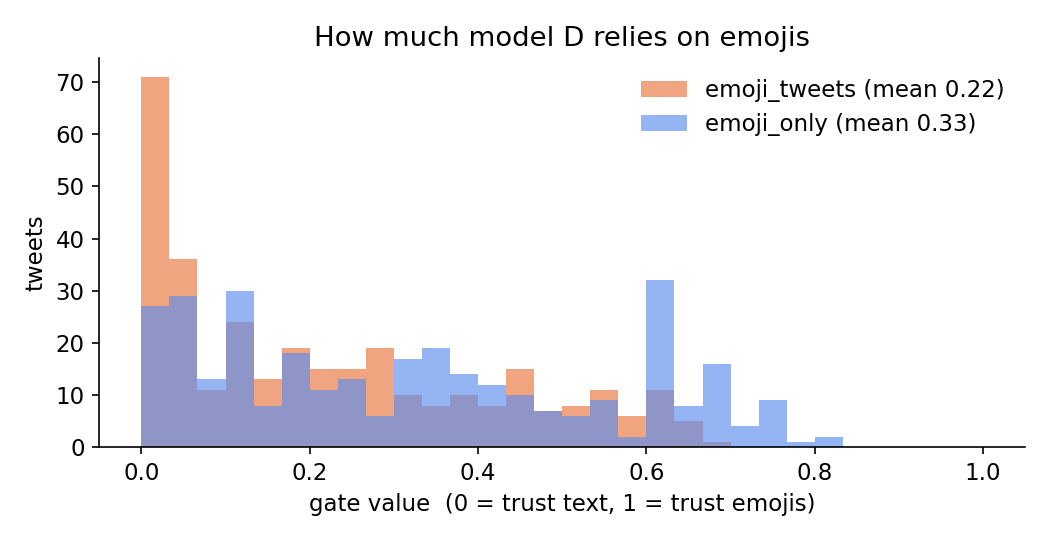

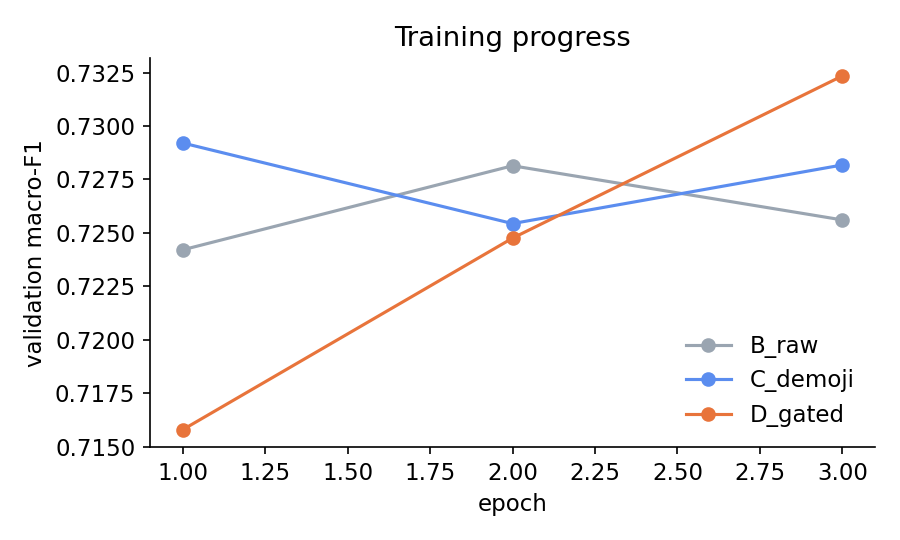

In [ ]:
from IPython.display import Image, display
for f in ["macro_f1_comparison.png", "confusion_emoji_tweets.png"]:
    p = os.path.join(ART, "figures", f)
    if os.path.exists(p):
        display(Image(filename=p, width=720))

## Live predictions

In [6]:
NAMES = esl.SentimentPredictor.MODEL_NAMES

def explain(text):
    r = predictor.predict(text)
    rows = [{"model": NAMES[k], "prediction": v["label"],
             **{f"p_{l}": round(float(p), 3) for l, p in zip(esl.LABELS, v["probs"])}} for k, v in r.items()]
    print(f"\nInput: {text}")
    display(pd.DataFrame(rows).set_index("model"))
    d = r["D"]
    if d["emoji_weights"]:
        print(f"Gate: {d['gate']:.0%} emoji / {1 - d['gate']:.0%} text   |   emoji attention: "
              + "  ".join(f"{e} {w:.2f}" for e, w in d["emoji_weights"]))
    else:
        print("Gate: no emojis -> 100% text branch")

for s in ["exam tomorrow 😭😭", "😡😡😡", "😍🔥🔥", "🙂🙂😡",
          "great, another monday 🙂", "lol i failed 😂", "the bus was late again", "🤔"]:
    explain(s)


Input: exam tomorrow 😭😭


,prediction,p_negative,p_neutral,p_positive
model,,,,
B: DistilBERT (raw emojis),neutral,0.004,0.863,0.133
C: DistilBERT (demojized),negative,0.555,0.398,0.047
D: Gated emoji model (ours),neutral,0.337,0.392,0.272


Gate: 63% emoji / 37% text   |   emoji attention: 😭 0.50  😭 0.50

Input: 😡😡😡


,prediction,p_negative,p_neutral,p_positive
model,,,,
B: DistilBERT (raw emojis),neutral,0.085,0.614,0.302
C: DistilBERT (demojized),negative,0.822,0.153,0.025
D: Gated emoji model (ours),negative,0.992,0.007,0.000


Gate: 1% emoji / 99% text   |   emoji attention: 😡 0.33  😡 0.33  😡 0.33

Input: 😍🔥🔥


,prediction,p_negative,p_neutral,p_positive
model,,,,
B: DistilBERT (raw emojis),neutral,0.085,0.614,0.302
C: DistilBERT (demojized),positive,0.004,0.141,0.855
D: Gated emoji model (ours),positive,0.012,0.059,0.929


... (7 outputs left out)

,prediction,p_negative,p_neutral,p_positive
model,,,,
B: DistilBERT (raw emojis),negative,0.741,0.252,0.007
C: DistilBERT (demojized),neutral,0.364,0.609,0.028
D: Gated emoji model (ours),negative,0.777,0.203,0.021


Gate: no emojis -> 100% text branch

Input: 🤔


,prediction,p_negative,p_neutral,p_positive
model,,,,
B: DistilBERT (raw emojis),neutral,0.085,0.614,0.302
C: DistilBERT (demojized),neutral,0.043,0.812,0.145
D: Gated emoji model (ours),neutral,0.348,0.516,0.136


Gate: 39% emoji / 61% text   |   emoji attention: 🤔 1.00


In [7]:
# Type your own sentence (works with emojis only, text only, or both)
try:
    import ipywidgets as widgets
    box = widgets.Text(placeholder="type a sentence with emojis…", layout=widgets.Layout(width="70%"))
    btn = widgets.Button(description="Predict", button_style="primary")
    out = widgets.Output()
    def on_click(_):
        with out:
            out.clear_output(); explain(box.value)
    btn.on_click(on_click); box.on_submit(on_click)
    display(widgets.HBox([box, btn]), out)
except Exception:
    while True:
        s = input("Sentence (blank to stop): ").strip()
        if not s:
            break
        explain(s)

## Browse saved test predictions

In [8]:
pe = pd.read_csv(os.path.join(ART, "predictions", "emoji_tweets.csv"))
lab = dict(enumerate(esl.LABELS))
for c in ["label", "B_raw", "C_demoji", "D_gated"]:
    pe[c] = pe[c].map(lab)
pd.set_option("display.max_colwidth", 120)
print("Emoji tweets where D is right and C is wrong:")
display(pe[(pe.D_gated == pe.label) & (pe.C_demoji != pe.label)].head(10)[["text", "label", "C_demoji", "D_gated", "D_gate"]])
print("Where D trusted the text most (lowest gate):")
display(pe.nsmallest(10, "D_gate")[["text", "label", "D_gated", "D_gate"]])

Emoji tweets where D is right and C is wrong:


,text,label,C_demoji,D_gated,D_gate
13,I FORGOT HIS TAIL 😂 #BeautyAndTheBeast,neutral,positive,neutral,0.6235
25,When your friends come back from college for thanksgiving break😬😂😂 @user @user @user,neutral,positive,neutral,0.5767
43,Mannequin Challenge Part 2. Peep me being fat with the whipped cream 😂 #mannequinchallenge,neutral,positive,neutral,0.6245
46,New tumblr post: @user New tumblr post: @user @user yo! Hot #uber driver last night 😝 #T…,positive,neutral,positive,0.6084
52,@user from @user - 🍑Shake your Bon-bon 🍑 @user #rickymartin #onewor…,positive,neutral,positive,0.3279
73,This week; Scouts are working towards their next level of emergency aid badge & both Cubs & Beavers are making Chris...,positive,neutral,positive,0.2410
79,can you roll up to my house with roses on valentines? 🤔🌹 @user,positive,neutral,positive,0.2172
93,"""If you are traveling with the samsung galaxy note 7, please leave it at the service desk and we will be happy to th...",neutral,positive,neutral,0.5991
115,@user @user 😂 She's new to vegetarianism! I'm sure shell expand her range soon and be demanding more taxing foodstuffs.,neutral,positive,neutral,0.5562
149,@user I went to type your name in the search bar..But the #NationalFastFoodDay popped up instead. Same thing right?😂...,neutral,positive,neutral,0.6133


Where D trusted the text most (lowest gate):


,text,label,D_gated,D_gate
269,Loser in Chief 😡#trumptransitionteam #notmypresident #fucktrump #jewishresistance…,negative,negative,0.0011
28,Reckless Moron. 😡🌪🇺🇸#trumptransitionteam #notmypresident #fucktrump #jewishresistance…,negative,negative,0.0013
232,@user AMAZES ME THAT MORONS WHO CLAIM THEY R RIGHT WING CONSERVATIVE CAN ONLY SPEW VENOM NEVER A SOLUTION 2ANY PROBL...,negative,negative,0.0021
71,America's Nightmare. 🇺🇸😱💤#trumptransitionteam #notmypresident #fucktrump #nohateinwhitehouse…,negative,negative,0.0024
31,#GilmoreGirlsTop4 1.Sukie2.Luke3.Kurk4.Jess I can't wait for the new series to start! 😍✨🎉,positive,positive,0.0032
57,Finally time to see #FantasticBeasts! Going with my dad cuz he loves #HarryPotter magic too and is the only series h...,positive,positive,0.0033
162,@user @user @user losing their cool because the refs are one sided. 😡,negative,negative,0.0042
211,working on the New Years & Valentines collection.😍 this is lit cant wait to reveal,positive,positive,0.0047
24,some of my new favorite otps from #fantasticbeasts 😍😍,positive,positive,0.0050
266,"We love you,@user! We are always #StillWithHer! 💙 You deserved to win!#recount #faithlesselectors #AuditTheVote You ...",positive,positive,0.0050


## Streamlit front-end
The first cell writes `app.py`, and the second starts it in the background. Then open **http://localhost:8501** in your browser.
This needs `streamlit` installed beforehand (`pip install streamlit`, while you still have internet). It runs on a laptop; Kaggle notebooks can't expose a local web port.

In [9]:
# %%writefile app.py
# import os, sys
# os.environ["HF_HUB_OFFLINE"] = "1"
# os.environ["TRANSFORMERS_OFFLINE"] = "1"
# import pandas as pd
# import streamlit as st

# ART = os.environ.get("EMOJI_ART", "emoji_sentiment_artifacts")
# sys.path.insert(0, ART)
# import emoji_sentiment_lib as esl

# st.set_page_config(page_title="Emoji Sentiment", page_icon="😊", layout="centered")

# @st.cache_resource(show_spinner="Loading models from disk…")
# def load_predictor():
#     return esl.SentimentPredictor(ART)

# predictor = load_predictor()
# NAMES = esl.SentimentPredictor.MODEL_NAMES
# FACE = {"negative": "😠", "neutral": "😐", "positive": "😊"}

# st.title("Emoji-based Sentiment Classification")
# st.caption("DistilBERT baselines (B, C) vs our gated text + emoji model (D) · runs fully offline")

# examples = ["", "😡😡😡", "😍🔥🔥", "🙂🙂😡", "exam tomorrow 😭😭", "great, another monday 🙂",
#             "lol i failed 😂", "the bus was late again"]
# ex = st.selectbox("Try an example, or type your own below", examples, format_func=lambda s: s or "—")
# text = st.text_area("Your text", value=ex, height=90, placeholder="type a sentence with emojis…")

# if st.button("Predict", type="primary") and text.strip():
#     r = predictor.predict(text.strip())
#     d = r["D"]
#     st.subheader(f"{FACE[d['label']]}  {d['label'].upper()}")
#     st.caption("Prediction from model D (ours)")
#     for lab, p in zip(esl.LABELS, d["probs"]):
#         st.progress(float(p), text=f"{lab}: {p:.1%}")

#     if d["emoji_weights"]:
#         st.markdown(f"**Gate:** {d['gate']:.0%} emoji branch · {1 - d['gate']:.0%} text branch")
#         cols = st.columns(len(d["emoji_weights"]))
#         for col, (e, w) in zip(cols, d["emoji_weights"]):
#             col.metric(e, f"{w:.2f}")
#         st.caption("Number under each emoji = its attention weight inside the emoji branch")
#     else:
#         st.markdown("**Gate:** no emojis found → 100% text branch")

#     st.markdown("#### All three models")
#     rows = [{"model": NAMES[k], "prediction": f"{FACE[v['label']]} {v['label']}",
#              **{l: round(float(x), 3) for l, x in zip(esl.LABELS, v["probs"])}} for k, v in r.items()]
#     st.dataframe(pd.DataFrame(rows).set_index("model"))

# with st.expander("Saved test-set results"):
#     res = pd.read_csv(os.path.join(ART, "results.csv"))
#     order = ["full_test", "emoji_tweets", "emoji_only"]
#     st.markdown("**Macro-F1**")
#     st.dataframe(res.pivot(index="model", columns="eval_set", values="macro_f1").round(4)[order])
#     for f in ["macro_f1_comparison.png", "confusion_emoji_tweets.png", "gate_distribution.png"]:
#         p = os.path.join(ART, "figures", f)
#         if os.path.exists(p):
#             st.image(p)

Overwriting app.py


In [13]:
# Start the Streamlit app in the background (the notebook stays usable)
import subprocess, time, importlib.util
if importlib.util.find_spec("streamlit") is None:
    print("streamlit is not installed -> run `pip install streamlit` (needs internet once)")
else:
    app_log = open("streamlit.log", "w")
    app_proc = subprocess.Popen(
        [sys.executable, "-m", "streamlit", "run", "app.py", "--server.port", "8501",
         "--server.headless", "true", "--browser.gatherUsageStats", "false"],
        env=dict(os.environ, EMOJI_ART=ART), stdout=app_log, stderr=subprocess.STDOUT)
    time.sleep(6)
    if app_proc.poll() is None:
        print("App running -> open http://localhost:8501  (first prediction loads the models, ~10-20 s)")
    else:
        print("App failed to start:\n" + open("streamlit.log").read())

App running -> open http://localhost:8501  (first prediction loads the models, ~10-20 s)


In [11]:
# Stop the app when you're done
app_proc.terminate()
print("Streamlit stopped")

Streamlit stopped
